Task 1: Verify your Google Cloud environment setup, including capturing proof of your active cloud notebook instance or billing credit balance.

Proof of active cloud notebook
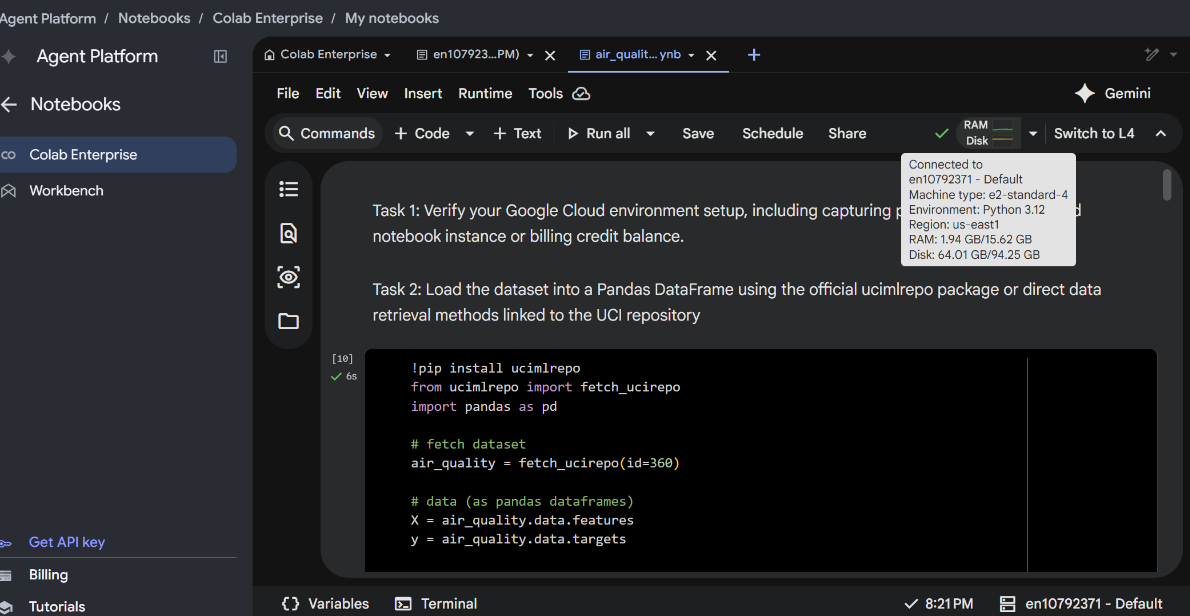


Proof of billing credits
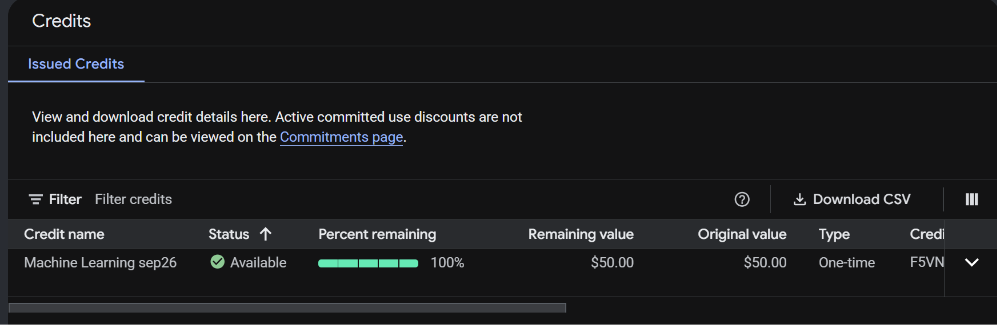

Task 2: Load the dataset into a Pandas DataFrame using the official ucimlrepo package or direct data retrieval methods linked to the UCI repository

In [28]:
!pip install ucimlrepo
from ucimlrepo import fetch_ucirepo
import pandas as pd

# fetch dataset
air_quality = fetch_ucirepo(id=360)

# data (as pandas dataframes)
X = air_quality.data.features
y = air_quality.data.targets

# metadata
print(air_quality.metadata)

# variable information
print(air_quality.variables)

# 2. Combine features and targets into a single pandas DataFrame
air = pd.concat([air_quality.data.features, air_quality.data.targets], axis=1)

{'uci_id': 360, 'name': 'Air Quality', 'repository_url': 'https://archive.ics.uci.edu/dataset/360/air+quality', 'data_url': 'https://archive.ics.uci.edu/static/public/360/data.csv', 'abstract': 'Contains the responses of a gas multisensor device deployed on the field in an Italian city. Hourly responses averages are recorded along with gas concentrations references from a certified analyzer. ', 'area': 'Computer Science', 'tasks': ['Regression'], 'characteristics': ['Multivariate', 'Time-Series'], 'num_instances': 9358, 'num_features': 15, 'feature_types': ['Real'], 'demographics': [], 'target_col': None, 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2008, 'last_updated': 'Sun Mar 10 2024', 'dataset_doi': '10.24432/C59K5F', 'creators': ['Saverio Vito'], 'intro_paper': {'ID': 420, 'type': 'NATIVE', 'title': 'On field calibration of an electronic nose for benzene estimation in an urban pollution monitoring scenario', 'authors': 

Task 3: Use structural inspection methods (head(), info(), describe()) to analyze the dataset structure and examine feature distributions across sensor and meteorological variables.

In [29]:
air.head()

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,3/10/2004,18:00:00,2.6,1360,150,11.9,1046,166,1056,113,1692,1268,13.6,48.9,0.7578
1,3/10/2004,19:00:00,2.0,1292,112,9.4,955,103,1174,92,1559,972,13.3,47.7,0.7255
2,3/10/2004,20:00:00,2.2,1402,88,9.0,939,131,1140,114,1555,1074,11.9,54.0,0.7502
3,3/10/2004,21:00:00,2.2,1376,80,9.2,948,172,1092,122,1584,1203,11.0,60.0,0.7867
4,3/10/2004,22:00:00,1.6,1272,51,6.5,836,131,1205,116,1490,1110,11.2,59.6,0.7888


In [30]:
air.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9357 entries, 0 to 9356
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   object 
 1   Time           9357 non-null   object 
 2   CO(GT)         9357 non-null   float64
 3   PT08.S1(CO)    9357 non-null   int64  
 4   NMHC(GT)       9357 non-null   int64  
 5   C6H6(GT)       9357 non-null   float64
 6   PT08.S2(NMHC)  9357 non-null   int64  
 7   NOx(GT)        9357 non-null   int64  
 8   PT08.S3(NOx)   9357 non-null   int64  
 9   NO2(GT)        9357 non-null   int64  
 10  PT08.S4(NO2)   9357 non-null   int64  
 11  PT08.S5(O3)    9357 non-null   int64  
 12  T              9357 non-null   float64
 13  RH             9357 non-null   float64
 14  AH             9357 non-null   float64
dtypes: float64(5), int64(8), object(2)
memory usage: 1.1+ MB


In [31]:
air.describe()

,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
count,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000
mean,-34.207524,1048.990061,-159.090093,1.865683,894.595276,168.616971,794.990168,58.148873,1391.479641,975.072032,9.778305,39.485380,-6.837604
std,77.657170,329.832710,139.789093,41.380206,342.333252,257.433866,321.993552,126.940455,467.210125,456.938184,43.203623,51.216145,38.976670
min,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000
25%,0.600000,921.000000,-200.000000,4.000000,711.000000,50.000000,637.000000,53.000000,1185.000000,700.000000,10.900000,34.100000,0.692300
50%,1.500000,1053.000000,-200.000000,7.900000,895.000000,141.000000,794.000000,96.000000,1446.000000,942.000000,17.200000,48.600000,0.976800
75%,2.600000,1221.000000,-200.000000,13.600000,1105.000000,284.000000,960.000000,133.000000,1662.000000,1255.000000,24.100000,61.900000,1.296200
max,11.900000,2040.000000,1189.000000,63.700000,2214.000000,1479.000000,2683.000000,340.000000,2775.000000,2523.000000,44.600000,88.700000,2.231000


Task 4: Identify and handle implicit missing data values (such as the standard -200 sentinel values present in the air quality dataset) and implement a structured imputation strategy using Scikit-Learn's SimpleImputer

In [32]:
import numpy as np
from sklearn.impute import SimpleImputer

a_clean = air.copy()

# Find -200 values
match_column = (air == -200).sum()
print(match_column)

# Replace -200 values
imputer = SimpleImputer(missing_values= -200, strategy='median')

missing = a_clean.select_dtypes(include=[np.int64, np.float64]).columns

# 3. Fit and transform the data
a_clean[missing] = imputer.fit_transform(a_clean[missing])

print('------------------------------------------------------------------------')
cleaned = (a_clean == -200).sum()
print(cleaned)


Date                0
Time                0
CO(GT)           1683
PT08.S1(CO)       366
NMHC(GT)         8443
C6H6(GT)          366
PT08.S2(NMHC)     366
NOx(GT)          1639
PT08.S3(NOx)      366
NO2(GT)          1642
PT08.S4(NO2)      366
PT08.S5(O3)       366
T                 366
RH                366
AH                366
dtype: int64
------------------------------------------------------------------------
Date             0
Time             0
CO(GT)           0
PT08.S1(CO)      0
NMHC(GT)         0
C6H6(GT)         0
PT08.S2(NMHC)    0
NOx(GT)          0
PT08.S3(NOx)     0
NO2(GT)          0
PT08.S4(NO2)     0
PT08.S5(O3)      0
T                0
RH               0
AH               0
dtype: int64


Task 5: Isolate numerical and categorical features, then build a Scikit-Learn ColumnTransformer and Pipeline that applies appropriate scaling (StandardScaler or MinMaxScaler) to numerical columns and necessary encoding to categorical/temporal features.

In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler
from sklearn.pipeline import Pipeline

# Because Date and Time would create too many unique categorical values, I will
# parse and feature extract the values (similar to how it is done in the spam example)
# so that I can group them into categories based on day, month, and hour.
# Combine Date and Time strings into a true datetime format
a_clean['Timestamp'] = pd.to_datetime(a_clean['Date'] + ' ' + a_clean['Time'], format='mixed')

# Extract components required for tracking pollutant variations (e.g., rush hour, season)
a_clean['Hour'] = a_clean['Timestamp'].dt.hour
a_clean['Month'] = a_clean['Timestamp'].dt.month
a_clean['DayOfWeek'] = a_clean['Timestamp'].dt.dayofweek

# Drop the raw text string columns
a_clean = a_clean.drop(columns=['Date', 'Time', 'Timestamp'])

#Taking out target value. I isolated NO2 to be my target value.
# NO2 is the most broadly responsible pollutant for unhealthy air.
x_var = a_clean.drop('NO2(GT)', axis = 1)
y_var = a_clean['NO2(GT)']

# Perform Quantile Binning on the Target vector (y) -> Classes 0, 1, 2
y_var = pd.qcut(a_clean['NO2(GT)'], q=3, labels=[0, 1, 2]).astype(int)

#Separation of numerical and categorical data
cat_var = ['Hour', 'Month', 'DayOfWeek']
num_var = [col for col in x_var.columns if col not in cat_var]

# Create pipelines for Minmax and StandardScaler
preprocessor_standard = ColumnTransformer([
    ("num", StandardScaler(), num_var),
    ("cat", OneHotEncoder(), cat_var),
])

preprocessor_minmax = ColumnTransformer([
    ("num", MinMaxScaler(), num_var),
    ("cat", OneHotEncoder(), cat_var),
])

Task 6: Train classification models to predict air quality categories using standard logistic/softmax regression and an SGDClassifier configured with custom loss functions and hyperparameters, evaluating convergence speed and performance.

In [42]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Split train and test data
X_train, X_test, y_train, y_test = train_test_split(x_var, y_var, test_size=0.2, random_state=42)


# Pair your 2 preprocessors with the 2 required classification architectures
# Done because question 4 in analysis section asks to compare Standard Scaler and MinMax Scaler
evaluation_matrix = [
    {
        'name': 'Softmax Regression + StandardScaler',
        'preprocessor': preprocessor_standard,
        'model': LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=2000, random_state=42)
    },
    {
        'name': 'Softmax Regression + MinMaxScaler',
        'preprocessor': preprocessor_minmax,
        'model': LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=2000, random_state=42)
    },
    {
        'name': 'SGDClassifier + StandardScaler',
        'preprocessor': preprocessor_standard,
        'model': SGDClassifier(loss='log_loss', max_iter=2000, tol=1e-3, random_state=42)
    },
    {
        'name': 'SGDClassifier + MinMaxScaler',
        'preprocessor': preprocessor_minmax,
        'model': SGDClassifier(loss='log_loss', max_iter=2000, tol=1e-3, random_state=42)
    }
]

# Storage list to compile a summary
task6_summary_records = []

# Transform and fit modesl
for run in evaluation_matrix:
    print(f"\n" + "-"*80)
    print(f"RUNNING PIPELINE: {run['name']}")
    print("-"*80)

    current_preprocessor = run['preprocessor']
    current_model = run['model']

    # Fit and transform training features
    X_train_transformed = current_preprocessor.fit_transform(X_train)
    X_test_transformed = current_preprocessor.transform(X_test)

    # Train the classification model
    current_model.fit(X_train_transformed, y_train)

    # Extract total iterations required to stabilize weights (handles shapes safely)
    iterations = current_model.n_iter_
    if isinstance(iterations, np.ndarray):
        iterations = iterations.max()

    print(f"Convergence Speed: Model stabilized and stopped training at iteration: {iterations}")

    # B. Evaluate Performance
    y_pred = current_model.predict(X_test_transformed)
    acc = accuracy_score(y_test, y_pred)

    print(f"Overall Test Accuracy: {acc:.4%}")
    print("\nTest Classification Report:")
    print(classification_report(y_test, y_pred))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    # Append the results into our tracking catalog
    task6_summary_records.append({
        'Pipeline Setup Configuration': run['name'],
        'Convergence Speed (Epochs/Iters)': iterations,
        'Test Dataset Accuracy': f"{acc:.2%}"
    })

# Print Results
print("\n" + "-"*80)
print("Final Performance & convergence speed comparison")
print("-"*80)
df_task6_summary = pd.DataFrame(task6_summary_records)
print(df_task6_summary.to_string(index=False))
print("-"*80)



--------------------------------------------------------------------------------
RUNNING PIPELINE: Softmax Regression + StandardScaler
--------------------------------------------------------------------------------


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Convergence Speed: Model stabilized and stopped training at iteration: 82
Overall Test Accuracy: 79.8077%

Test Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.83      0.81       631
           1       0.71      0.68      0.69       611
           2       0.89      0.88      0.88       630

    accuracy                           0.80      1872
   macro avg       0.80      0.80      0.80      1872
weighted avg       0.80      0.80      0.80      1872


Confusion Matrix:
[[524 101   6]
 [129 418  64]
 [  5  73 552]]

--------------------------------------------------------------------------------
RUNNING PIPELINE: Softmax Regression + MinMaxScaler
--------------------------------------------------------------------------------


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Convergence Speed: Model stabilized and stopped training at iteration: 74
Overall Test Accuracy: 78.4188%

Test Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.81      0.79       631
           1       0.69      0.65      0.67       611
           2       0.87      0.89      0.88       630

    accuracy                           0.78      1872
   macro avg       0.78      0.78      0.78      1872
weighted avg       0.78      0.78      0.78      1872


Confusion Matrix:
[[513 109   9]
 [144 396  71]
 [  6  65 559]]

--------------------------------------------------------------------------------
RUNNING PIPELINE: SGDClassifier + StandardScaler
--------------------------------------------------------------------------------
Convergence Speed: Model stabilized and stopped training at iteration: 40
Overall Test Accuracy: 75.5342%

Test Classification Report:
              precision    recall  f1-score   support

           0     

Task 7: Transition to regression tasks to predict continuous pollutant concentrations, implementing baseline Linear Regression alongside Ridge (L2) and Lasso (L1) regularization, and analyzing how the regularization parameter impacts feature coefficients and feature selection.

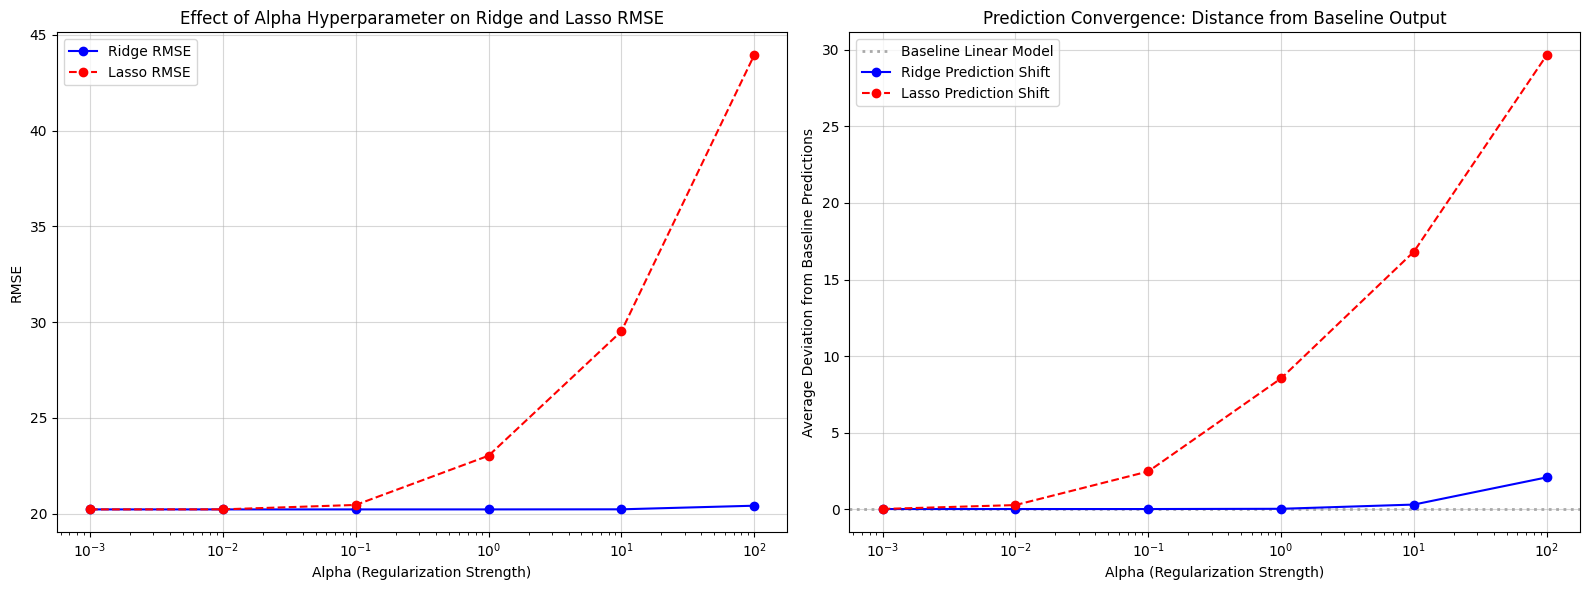


Lasso Coefficient and Feature Change
  Alpha  Active_Features  Total_Features Ridge_Slope_Dist Lasso_Slope_Dist                                 Dropped_Sample
  0.001               53              55             0.22             3.62                           Month_5, DayOfWeek_1
  0.010               52              55             0.22             3.18                  Hour_15, Hour_23, DayOfWeek_1
  0.100               39              55             0.22            20.09          PT08.S4(NO2), Hour_0, Hour_9, Hour_10
  1.000                7              55             0.50            59.27 PT08.S1(CO), NMHC(GT), C6H6(GT), PT08.S2(NMHC)
 10.000                4              55             3.92            64.25        CO(GT), PT08.S1(CO), NMHC(GT), C6H6(GT)
100.000                0              55            21.14            68.76        CO(GT), PT08.S1(CO), NMHC(GT), C6H6(GT)


In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error

# Ensure your target y_var is the raw continuous pollutant column for regression!
raw_continuous_y = a_clean['NO2(GT)']

# Transform features using your preprocessor from Task 5
X_transformed = preprocessor_standard.fit_transform(x_var)
feature_names = preprocessor_standard.get_feature_names_out()
short_names = [name.split('__')[-1] for name in feature_names]

# Generate our benchmark Baseline Linear Regression model
baseline_model = LinearRegression().fit(X_transformed, raw_continuous_y)
y_pred_baseline = baseline_model.predict(X_transformed)
baseline_coefs = baseline_model.coef_

# Define the exact log-scale alpha array matching your target chart layout
test_alphas = [10**-3, 10**-2, 10**-1, 10**0, 10**1, 10**2]

# Storage arrays for metric collections
ridge_rmse_list = []
lasso_rmse_list = []
ridge_pred_shifts = []
lasso_pred_shifts = []

# List to compile feature selection timeline metrics
elimination_records = []

# create flow to test and compare tuning of alpha with ridge and lasso models
for a in test_alphas:
    model_ridge = Ridge(alpha=a, random_state=42).fit(X_transformed, raw_continuous_y)
    model_lasso = Lasso(alpha=a, max_iter=30000, random_state=42).fit(X_transformed, raw_continuous_y)

    # Generate model predictions
    y_pred_ridge = model_ridge.predict(X_transformed)
    y_pred_lasso = model_lasso.predict(X_transformed)

    # Collect Performance Metrics (RMSE)
    ridge_rmse_list.append(np.sqrt(mean_squared_error(raw_continuous_y, y_pred_ridge)))
    lasso_rmse_list.append(np.sqrt(mean_squared_error(raw_continuous_y, y_pred_lasso)))

    # Collect Prediction Deviation (Shift from Baseline Predictions)
    ridge_pred_shifts.append(np.mean(np.abs(y_pred_baseline - y_pred_ridge)))
    lasso_pred_shifts.append(np.mean(np.abs(y_pred_baseline - y_pred_lasso)))

    # Track Coefficient Changes & Feature Selection Status
    zeroed_indices = np.where(model_lasso.coef_ == 0)[0]
    dropped_features = [short_names[i] for i in zeroed_indices]

    # Track the geometric coefficient distance away from baseline slopes
    r_coef_dist = np.linalg.norm(baseline_coefs - model_ridge.coef_)
    l_coef_dist = np.linalg.norm(baseline_coefs - model_lasso.coef_)

    elimination_records.append({
        'Alpha': a,
        'Active_Features': len(short_names) - len(dropped_features),
        'Total_Features': len(short_names),
        'Ridge_Slope_Dist': r_coef_dist,
        'Lasso_Slope_Dist': l_coef_dist,
        'Dropped_Sample': ", ".join(dropped_features[:4]) if dropped_features else "None"
    })


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Effect of Alpha on Ridge and Lasso Performance (RMSE)
ax1.plot(test_alphas, ridge_rmse_list, label='Ridge RMSE', color='blue', marker='o', linestyle='-')
ax1.plot(test_alphas, lasso_rmse_list, label='Lasso RMSE', color='red', marker='o', linestyle='--')
ax1.set_xscale('log')
ax1.set_xlabel('Alpha (Regularization Strength)')
ax1.set_ylabel('RMSE')
ax1.set_title('Effect of Alpha Hyperparameter on Ridge and Lasso RMSE')
ax1.legend()
ax1.grid(True, linestyle='-', alpha=0.5)

# Subplot 2: How Changing Alpha Pulls Predictions Away From Baseline
ax2.axhline(0, color='darkgray', linestyle=':', linewidth=2, label='Baseline Linear Model')
ax2.plot(test_alphas, ridge_pred_shifts, label='Ridge Prediction Shift', color='blue', marker='o', linestyle='-')
ax2.plot(test_alphas, lasso_pred_shifts, label='Lasso Prediction Shift', color='red', marker='o', linestyle='--')
ax2.set_xscale('log')
ax2.set_xlabel('Alpha (Regularization Strength)')
ax2.set_ylabel('Average Deviation from Baseline Predictions')
ax2.set_title('Prediction Convergence: Distance from Baseline Output')
ax2.legend()
ax2.grid(True, linestyle='-', alpha=0.5)

plt.tight_layout()
plt.show()


print("\n" + "="*80)
print("Lasso Coefficient and Feature Change")
print("="*80)
df_report = pd.DataFrame(elimination_records)
print(df_report.to_string(index=False, formatters={
    'Ridge_Slope_Dist': '{:,.2f}'.format,
    'Lasso_Slope_Dist': '{:,.2f}'.format
}))
print("="*80)


Task 8: Provide a final documentation cell or appendix section containing a screenshot or export of your Google Cloud billing or resource utilization dashboard showing active credit consumption.

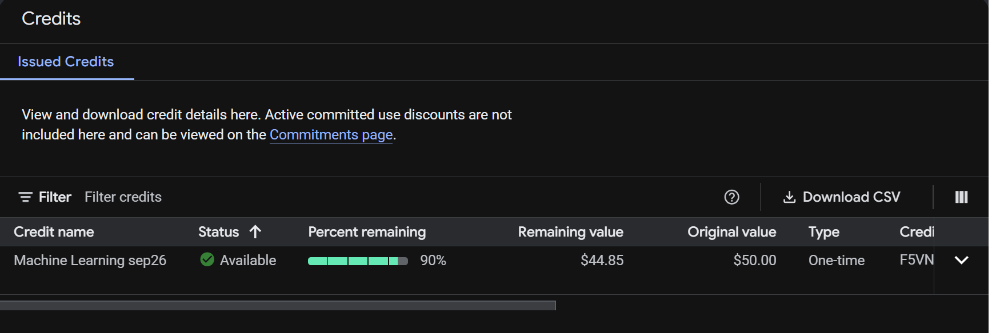